# 06. Modelado de series de tiempo (Tarea B)

Una variable por archivo, cada una con un problema distinto:

| Archivo | Variable | Paso | Por qué esta |
|---|---|---|---|
| 367 meteorológica | `t`, temperatura (°C) | 1 h | Ciclo diurno marcado y casi sin huecos: es el caso base para comparar modelos estacionales. Es además la variable que se usa para validar la coherencia con humedad y radiación. |
| 6004 piranómetro | `radiacion` (W/m²) | 1 h, hora local | Única variable del archivo. Cero de noche y nubes de día: un ciclo determinista (el sol) más un ruido muy grande, que pone a prueba los intervalos. El archivo viene en UTC; `regularizar` ya lo pasó a hora local. |
| 35 pluviométrica | `p1`, lluvia (mm/h) | 1 h | Intermitente: la mayoría de las horas son cero. Uso `p1` y no el promedio de los dos balancines (justificación abajo). |
| 803 nivel | `nivel` (cm) | 10 min | Única variable del archivo y la más útil para alerta. Horizonte de 10 a 60 min. La media horaria aplana las crecientes (el pico llega unos 20 min después de la lluvia), por eso 10 min. |

Todo sale de `parte2/salidas/` (generado por `python -m siata.pipeline`). Las funciones están en `siata/series.py` y sus pruebas en `tests/test_series.py` (sin fuga de información, MASE, interpolación, conformal).

In [1]:
import sys; from pathlib import Path; sys.path.insert(0, str(Path.cwd().parent))
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

from siata import series as S
from siata.datos import DIR_SALIDAS
from siata.pipeline import DIR_RESULTADOS

INICIO = time.time()
FIGURAS = Path.cwd().parent / "figuras"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.6,
                     "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "legend.fontsize": 8, "legend.frameon": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 3)


def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"06_{nombre}.png", dpi=110, bbox_inches="tight")


CODIGO = {"t": "367", "radiacion": "6004", "p1": "35", "nivel": "803"}
UNIDAD = {"t": "°C", "radiacion": "W/m²", "p1": "mm/h", "nivel": "cm"}
TITULO = {"t": "Temperatura, 367", "radiacion": "Radiación, 6004", "p1": "Lluvia p1, 35", "nivel": "Nivel, 803"}
PERIODO = {"t": 24, "radiacion": 24, "p1": 24, "nivel": 144}  # pasos en 24 h

## B1. Preprocesamiento

Lo que ya hizo el paquete y por qué:

- Índice regular. `datos.regularizar` lleva cada archivo a una malla de un minuto en hora local: los minutos sin registro quedan en NaN (no se inventan), el centinela -999 pasa a NaN y queda marcado, y las marcas con segundos se llevan a su minuto. La 6004 se corrige de UTC a hora local.
- Solo datos que pasan el control propio. Temperatura y radiación: media horaria de los minutos con bandera buena, con al menos 75 % de cobertura (si no, la hora queda vacía). Lluvia: suma horaria de minutos buenos o sospechosos con 90 % de cobertura (la única sospecha en la 35 es el desacuerdo entre balancines, y quitarla borraba justo los aguaceros). Nivel: media de 10 min de los minutos con bandera 1, cobertura de 75 % y redondeo a 0,1 cm (viene en float32, valores como 2,700012).

Lo que se decide en este notebook:

- Dos series por variable. El objetivo es la serie limpia y nunca tiene imputados: contra ella se evalúa. La entrada es la misma serie con los huecos de hasta 3 pasos (3 h en las horarias, 30 min en el nivel) interpolados en el tiempo; solo alimenta los modelos y cada valor imputado queda marcado.
- Los huecos largos no se rellenan. ETS usa el último tramo continuo, ARIMA los salta con el filtro de Kalman y el gradient boosting acepta NaN en sus variables.
- La lluvia no se interpola: interpolar una acumulación inventa lluvia.
- Nivel desde el 3 de marzo de 2026. Ese día la estación cambió de comportamiento (EDA 02: línea base y ruido distintos, probable intervención no documentada). Entrenar con los dos regímenes mezcla dos instrumentos; abajo se muestra la diferencia.

In [2]:
CORTO = 3  # pasos: 3 h en las horarias, 30 min en el nivel
CAMBIO_803 = pd.Timestamp("2026-03-03")

t = S.serie_horaria("367_t")
rad = S.serie_horaria("6004_radiacion")
lluvia = S.serie_horaria("35_p1")
nivel_todo = S.nivel_10min()
nivel = nivel_todo.loc[CAMBIO_803:]
objetivo = {"t": t, "radiacion": rad, "p1": lluvia, "nivel": nivel}

entrada, imputado = {}, {}
for v in ("t", "radiacion", "nivel"):
    entrada[v], imputado[v] = S.rellenar_cortos(objetivo[v], CORTO)
entrada["p1"], imputado["p1"] = lluvia, pd.Series(False, index=lluvia.index)  # la lluvia no se interpola

filas = []
for v, s in objetivo.items():
    h = S.huecos(s)
    filas.append({"variable": v, "paso": s.index.freq.freqstr, "desde": s.index[0], "hasta": s.index[-1],
                  "pasos": len(s), "faltantes": int(s.isna().sum()), "huecos": len(h),
                  "hueco_mas_largo": int(h["pasos"].max()) if len(h) else 0,
                  "imputados_en_entrada": int(imputado[v].sum()), "sin_rellenar": int(entrada[v].isna().sum())})
pd.DataFrame(filas)

,variable,paso,desde,hasta,pasos,faltantes,huecos,hueco_mas_largo,imputados_en_entrada,sin_rellenar
0,t,h,2025-12-01 00:00:00,2026-04-30 23:00:00,3624,4,2,2,4,0
1,radiacion,h,2025-11-30 19:00:00,2026-04-30 18:00:00,3624,46,10,30,12,34
2,p1,h,2025-12-01 00:00:00,2026-04-30 23:00:00,3624,0,0,0,0,0
3,nivel,10min,2026-03-03 00:00:00,2026-04-30 23:50:00,8496,418,34,122,33,385


Dos verificaciones que sostienen decisiones de arriba: que `p1` y `p2` miden lo mismo, y que el nivel antes y después del 3 de marzo no se comporta igual.

In [3]:
h = pd.read_parquet(DIR_SALIDAS / "horario.parquet")[["35_p1", "35_p2"]].dropna()
print(f"lluvia total p1 {h['35_p1'].sum():.1f} mm, p2 {h['35_p2'].sum():.1f} mm; "
      f"correlación horaria {h.corr().iloc[0, 1]:.3f}; horas con p1 >= 0.254 mm: {(h['35_p1'] >= 0.254).mean():.1%}")
for nombre, s in [("antes del 3 mar", nivel_todo.loc[:CAMBIO_803 - pd.Timedelta("10min")]), ("desde el 3 mar", nivel)]:
    print(f"803 {nombre}: mediana {s.median():.2f} cm; mediana de |cambio en 10 min| {s.diff().abs().median():.2f} cm; "
          f"{s.notna().sum()} bloques con dato")

lluvia total p1 848.1 mm, p2 858.3 mm; correlación horaria 0.998; horas con p1 >= 0.254 mm: 8.7%
803 antes del 3 mar: mediana 2.47 cm; mediana de |cambio en 10 min| 0.58 cm; 12829 bloques con dato
803 desde el 3 mar: mediana 3.01 cm; mediana de |cambio en 10 min| 0.23 cm; 8078 bloques con dato


Por qué `p1` y no el promedio: los dos balancines miden lo mismo (correlación casi 1 y totales parecidos), así que el promedio casi no agrega información y sí crea valores que ningún sensor mide (una vuelta de un solo balancín daría 0,127 mm). Con `p1` el evento "llueve en la hora" tiene una definición física limpia: al menos una vuelta del balancín, 0,254 mm. `p2` sigue cumpliendo su papel de respaldo en el control de calidad (regla `p1_p2_difieren`).

## B2. Descomposición, estacionariedad y autocorrelación

STL robusto con periodo de un día (24 pasos en las horarias, 144 en el nivel) sobre el tramo continuo más largo de la entrada (STL no acepta huecos). La fuerza de la estacionalidad y de la tendencia se mide como 1 - var(residuo) / var(componente + residuo) (Hyndman y Athanasopoulos): cerca de 1 es fuerte, cerca de 0 no hay.

Las dos pruebas tienen hipótesis nulas opuestas, por eso se usan juntas:

- ADF: H0 = la serie tiene raíz unitaria (no es estacionaria). Un p-valor pequeño la rechaza.
- KPSS: H0 = la serie es estacionaria alrededor de una media. Un p-valor pequeño la rechaza.

Si ADF rechaza y KPSS no, la serie es estacionaria. Si las dos rechazan, no hay raíz unitaria pero el nivel medio se mueve (tendencia lenta, cambios de régimen o memoria larga): conviene modelar con componentes deterministas o diferenciar. KPSS reporta p-valores solo entre 0,01 y 0,10 (fuera de eso, se trunca).

In [4]:
def tramo_mas_largo(s):
    grupo = s.isna().cumsum()  # cada NaN abre un grupo nuevo; los datos seguidos comparten grupo
    ok = s.notna()
    largo = ok.groupby(grupo).transform("sum")
    return s[ok & (grupo == grupo[ok & (largo == largo[ok].max())].iloc[0])]


def lectura(adf_p, kpss_p):
    if adf_p < 0.05 and kpss_p >= 0.05:
        return "estacionaria"
    if adf_p < 0.05:
        return "sin raíz unitaria, pero la media se mueve"
    if kpss_p < 0.05:
        return "raíz unitaria: diferenciar"
    return "no concluyente"


pruebas, stl, tramo = [], {}, {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # kpss avisa cuando el p-valor cae fuera de su tabla
    for v in objetivo:
        y = tramo[v] = tramo_mas_largo(entrada[v])
        r = stl[v] = STL(y, period=PERIODO[v], robust=True).fit()
        adf_p, kpss_p = adfuller(y, autolag="AIC")[1], kpss(y, regression="c", nlags="auto")[1]
        pruebas.append({"variable": v, "desde": y.index[0], "hasta": y.index[-1], "n": len(y),
                        "fuerza_estacional": max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var()),
                        "fuerza_tendencia": max(0, 1 - r.resid.var() / (r.trend + r.resid).var()),
                        "ADF_p": adf_p, "KPSS_p": kpss_p, "lectura": lectura(adf_p, kpss_p)})
pd.DataFrame(pruebas)

,variable,desde,hasta,n,fuerza_estacional,fuerza_tendencia,ADF_p,KPSS_p,lectura
0,t,2025-12-01 00:00:00,2026-04-30 23:00:00,3624,0.848,0.451,9.584e-09,0.044,"sin raíz unitaria, pero la media se mueve"
1,radiacion,2025-12-23 12:00:00,2026-04-08 04:00:00,2537,0.842,0.091,2.599e-09,0.010,"sin raíz unitaria, pero la media se mueve"
2,p1,2025-12-01 00:00:00,2026-04-30 23:00:00,3624,0.055,0.015,0.000e+00,0.100,estacionaria
3,nivel,2026-03-17 11:10:00,2026-04-30 23:50:00,6413,0.592,0.192,2.483e-22,0.100,estacionaria


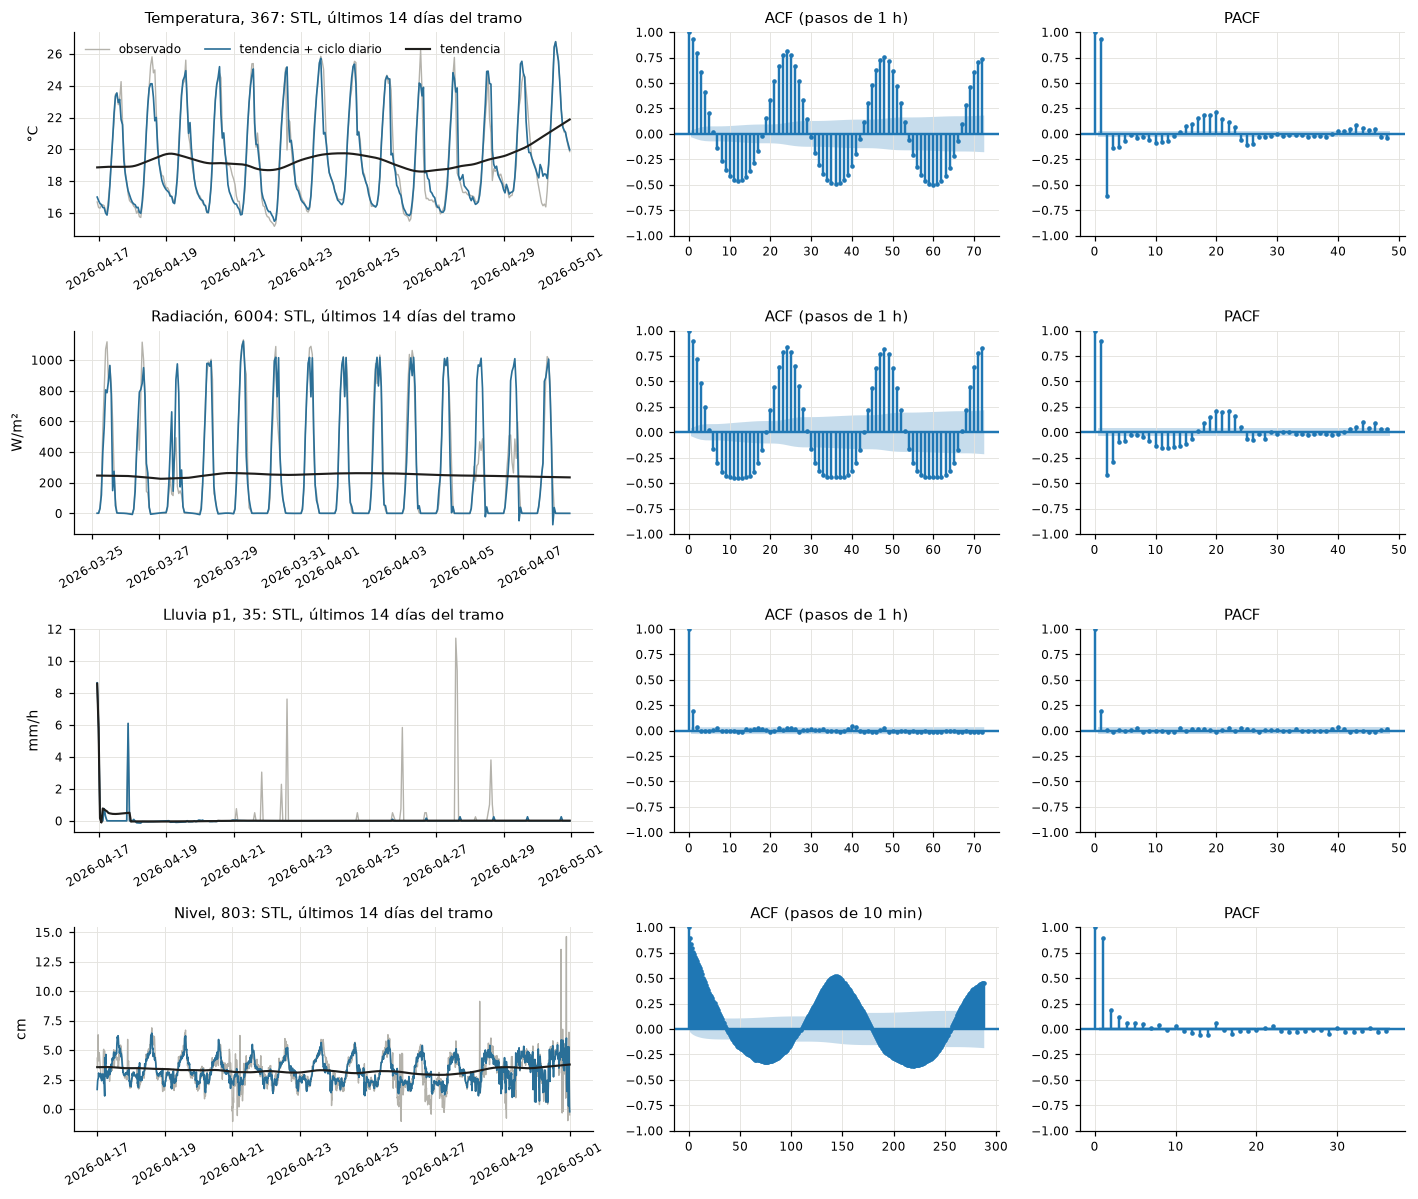

In [5]:
fig, ax = plt.subplots(4, 3, figsize=(13, 11), gridspec_kw={"width_ratios": [1.6, 1, 1]})
for i, v in enumerate(objetivo):
    r, y = stl[v], tramo[v]
    ventana = y.index[-1] - pd.Timedelta("14D")
    a = ax[i, 0]
    a.plot(y.loc[ventana:], color="#b4b2ab", lw=0.9, label="observado")
    a.plot((r.trend + r.seasonal).loc[ventana:], color="#2a6f97", lw=1.1, label="tendencia + ciclo diario")
    a.plot(r.trend.loc[ventana:], color="#1f1e1c", lw=1.4, label="tendencia")
    a.set(title=f"{TITULO[v]}: STL, últimos 14 días del tramo", ylabel=UNIDAD[v])
    a.tick_params(axis="x", rotation=30)
    rezagos = 3 * PERIODO[v] if v != "nivel" else 2 * PERIODO[v]
    plot_acf(y, lags=rezagos, ax=ax[i, 1], markersize=2, title=f"ACF ({'pasos de 1 h' if v != 'nivel' else 'pasos de 10 min'})")
    plot_pacf(y, lags=48 if v != "nivel" else 36, ax=ax[i, 2], markersize=2, method="ywm", title="PACF")
ax[0, 0].legend(loc="upper left", ncols=3)
fig.tight_layout()
guardar(fig, "descomposicion")

### Lectura de B2

- Temperatura: el ciclo diario domina (fuerza estacional 0,85) y la tendencia pesa (0,45) porque la media cambia de una semana a otra, por ejemplo el calentamiento del final de abril que se ve en la figura. ADF rechaza la raíz unitaria (p < 0,001) y KPSS rechaza la estacionariedad al 5 % (p = 0,044): no hay que diferenciar, pero el nivel medio se mueve. La ACF oscila con periodo de 24 h y casi no decae en tres días; la PACF corta después de los rezagos 1 y 2, con un grupo pequeño entre 15 y 23 h. Eso apunta a un autorregresivo corto encima del ciclo diario, y por eso se usa ETS con estación de 24 y, en el gradient boosting, rezagos de 0 a 3, 6, 12 y 23 h.
- Radiación: fuerza estacional 0,84 y de tendencia 0,09. Casi todo es el sol más el ruido de las nubes. Las dos pruebas rechazan (KPSS en su tope, p <= 0,01): la media diaria cambia con la nubosidad de cada semana. La ACF y la PACF tienen la misma forma que en la temperatura. El ciclo no hace falta estimarlo: se calcula (radiación extraterrestre g0).
- Lluvia: fuerza estacional 0,06 y de tendencia 0,015. STL no encuentra un ciclo útil en los montos horarios: pocos aguaceros dominan la varianza. ADF rechaza y KPSS no: estacionaria. Solo el rezago 1 sale con claridad de la banda en la ACF y la PACF (el rezago 2 de la ACF y el 40 de las dos apenas la pasan): lo que llovió en una hora dice algo de la siguiente y casi nada después. Esto anticipa que ningún modelo pronosticará montos a varias horas.
- Nivel (tramo continuo del 17 de marzo al 30 de abril): fuerza estacional 0,59. El ciclo diario de unos 2 cm visto en el EDA 02 se confirma a 10 min (la hipótesis de efecto térmico del sensor sigue sin verificar). ADF rechaza y KPSS no: estacionaria, como se espera de una quebrada que vuelve a su caudal base. La PACF la domina el rezago 1. Por eso el ARIMA del nivel no se diferencia: el AIC eligió ARIMA(2,0,1) con constante con el entrenamiento del primer origen.

## B3 y B4. Modelos y validación de origen móvil

Diseño común:

- Origen móvil con ventana creciente: en cada origen T el modelo ve solo datos con fecha <= T y pronostica los pasos siguientes. Horarias: 40 orígenes separados 25 h (así el origen recorre todas las horas del día) en las últimas 6 semanas, horizonte de 24 h. Nivel: un origen cada 50 min en las últimas 6 semanas, horizonte de 6 pasos (10 a 60 min).
- Solo se usan orígenes con dato observado en el propio origen. Así ningún valor interpolado de la entrada pudo tomar información posterior al origen.
- Los parámetros de ETS, ARIMA y gradient boosting se reestiman cada 7 orígenes en las horarias y cada 144 en el nivel (unos 5 días); entre reestimaciones el modelo incorpora los datos nuevos sin cambiar parámetros. Es lo que haría la operación y mantiene el notebook por debajo de 15 min.
- Referencias ingenuas en todas: persistencia (el último valor) y estacional de 24 h (el mismo momento del día anterior).
- Estadístico: ETS(A,N,A) en la temperatura; regresión con errores ARIMA sobre la radiación extraterrestre en la radiación; ARIMA en el nivel (órdenes elegidos por AIC solo con el entrenamiento del primer origen); TSB (Teunter, Syntetos y Babai) en la lluvia. Intervalos analíticos del modelo, salvo en TSB, que da el pronóstico y la probabilidad pero no intervalo.
- Aprendizaje automático: `HistGradientBoostingRegressor` con estrategia directa (un solo modelo con el horizonte h como variable, sin recursión), rezagos, media del último día, valor de hace 24 h y hora del objetivo en seno y coseno. En la radiación entra también la radiación extraterrestre de la hora objetivo (depende solo del reloj). En el nivel entra la lluvia de la 35 observada hasta el origen y el modelo aprende el cambio y(T + h) - y(T). En la lluvia, dos partes: un clasificador da la probabilidad de lluvia (>= 0,254 mm) y un regresor Poisson la cantidad si llueve; el pronóstico es su producto. Intervalos: regresión por cuantiles (10 y 90 %) ajustada luego con conformal secuencial (CQR).
- Métricas sobre la muestra común (filas con dato real y pronóstico de todos los modelos): MAE, RMSE y MASE. Escala de MASE: MAE de la ingenua estacional (m = 24) dentro del entrenamiento de cada origen en las horarias, y de la persistencia en el nivel. Nunca se evalúa contra valores imputados.

In [6]:
COLOR = {"persistencia": "#8d8b85", "ingenua_estacional_24h": "#c9a227", "ingenua_cero": "#cfcdc6",
         "climatologia_horaria": "#6a994e", "ets_ANA": "#2a6f97", "arima_g0": "#2a6f97", "arima": "#2a6f97",
         "tsb": "#2a6f97", "hgb": "#c8553d", "hgb_dos_partes": "#c8553d"}
CADA_H, CADA_N = 7, 144
pron, metr, cqr = {}, [], []


def juntar(mods, v):
    p = pd.concat([d.assign(modelo=k) for k, d in mods.items()], ignore_index=True)
    p["real"] = objetivo[v].reindex(p["fecha_hora"]).to_numpy()  # siempre contra la serie sin imputar
    return p.assign(codigo=CODIGO[v], variable=v)


def con_cqr(p, v, modelo, usar=None, minimo=None):
    # Cambia el intervalo de cuantiles del modelo de ML por su versión conformal (80 y 95 %) y guarda la comparación
    d = p[p["modelo"] == modelo].sort_values(["origen", "horizonte"]).reset_index(drop=True)
    u = None if usar is None else usar(d)
    c = S.conformal(d, 80, usar=u, minimo=minimo)
    c95 = S.conformal(d.assign(inf95=d["inf80"], sup95=d["sup80"]), 95, usar=u, minimo=minimo)
    c[["inf95", "sup95"]] = c95[["inf95", "sup95"]].to_numpy()
    ok = c["inf80"].notna() & c["real"].notna() & (True if u is None else u)
    for nombre, x in [("cuantiles", d), ("CQR", c)]:
        cqr.append({"variable": v, "modelo": modelo, "intervalo": nombre, "n": int(ok.sum()),
                    "cobertura80": x.loc[ok, "real"].between(x.loc[ok, "inf80"], x.loc[ok, "sup80"]).mean(),
                    "ancho80": (x.loc[ok, "sup80"] - x.loc[ok, "inf80"]).mean()})
    return pd.concat([p[p["modelo"] != modelo], c], ignore_index=True)


def orden_por_aic(y, candidatos, exog=None, tendencia="c"):
    aic = {}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for o in candidatos:
            aic[o] = SARIMAX(y, exog=exog, order=o, trend=tendencia).fit(disp=False).aic
    print("AIC:", {str(k): round(a, 1) for k, a in aic.items()})
    return min(aic, key=aic.get)

### Temperatura (367)

In [7]:
reloj = time.time()
o_t = S.origenes(t, 24, 40, 25)
avisos = []
mods = {"persistencia": S.persistencia(entrada["t"], o_t, 24),
        "ingenua_estacional_24h": S.estacional_ingenua(entrada["t"], o_t, 24, 24),
        "ets_ANA": S.ets(entrada["t"], o_t, 24, 24, cada=CADA_H, avisos=avisos)}
M = S.matriz_directa(entrada["t"], t, 24, [0, 1, 2, 3, 6, 12, 23], 24)
mods["hgb"] = S.hgb(M, o_t, cada=CADA_H)
p = con_cqr(juntar(mods, "t"), "t", "hgb")
escalas = {o: S.escala_mase(t, o, 24) for o in o_t}
pron["t"] = p
metr.append(S.metricas(p, escalas).assign(variable="t"))
print(f"{len(o_t)} orígenes, de {o_t[0]} a {o_t[-1]}; avisos de ETS: {len(avisos)}; {time.time() - reloj:.0f} s")
metr[-1]

40 orígenes, de 2026-03-20 08:00:00 a 2026-04-29 23:00:00; avisos de ETS: 0; 14 s


,modelo,MAE,RMSE,MASE,n_origenes,n,cobertura80,ancho80,cobertura95,ancho95,variable
0,persistencia,3.201,4.027,2.535,40,958,NaN,NaN,NaN,NaN,t
1,ingenua_estacional_24h,1.167,1.691,0.924,40,958,NaN,NaN,NaN,NaN,t
2,ets_ANA,1.197,1.660,0.948,40,958,0.915,6.359,0.977,9.726,t
3,hgb,0.994,1.397,0.787,40,958,0.843,3.463,0.964,4.910,t


### Radiación (6004)

La radiación extraterrestre horizontal g0 (media de la hora, en W/m²) depende solo de la fecha, la hora y la posición; se conoce de antemano para cualquier hora futura. El modelo estadístico es una regresión de la radiación sobre g0 con errores ARIMA. En las horas con g0 = 0 (sol bajo el horizonte toda la hora) el pronóstico y su intervalo se fijan en 0, y los valores negativos se recortan a 0, porque la radiación no puede ser negativa.

Las métricas de la radiación se calculan solo en horas con sol (g0 > 0), y la escala de MASE también: de noche todos los modelos aciertan el cero y esas horas inflarían la cobertura y bajarían el error sin decir nada útil.

In [8]:
reloj = time.time()
g0 = S.radiacion_extraterrestre(rad.index)
o_r = S.origenes(rad, 24, 40, 25)
X0 = g0.to_frame()
orden_r = orden_por_aic(entrada["radiacion"].loc[:o_r[0]], [(1, 0, 0), (2, 0, 0), (1, 0, 1), (2, 0, 1)], X0.loc[:o_r[0]])
mods = {"persistencia": S.persistencia(entrada["radiacion"], o_r, 24),
        "ingenua_estacional_24h": S.estacional_ingenua(entrada["radiacion"], o_r, 24, 24),
        "arima_g0": S.arima(entrada["radiacion"], o_r, 24, orden_r, exog=X0, cada=CADA_H)}
M = S.matriz_directa(entrada["radiacion"], rad, 24, [0, 1, 2, 3, 23], 24, futuras=g0)
mods["hgb"] = S.hgb(M, o_r, cada=CADA_H, minimo=0)
for k in ("arima_g0", "hgb"):
    d, cols = mods[k], ["pred", "inf80", "sup80", "inf95", "sup95"]
    d[cols] = d[cols].clip(lower=0)
    d.loc[g0.reindex(d["fecha_hora"]).to_numpy() == 0, cols] = 0.0
de_dia = lambda d: (g0.reindex(d["fecha_hora"]) > 0).to_numpy()
p = con_cqr(juntar(mods, "radiacion"), "radiacion", "hgb", usar=de_dia, minimo=0)
escalas = {o: S.escala_mase(rad.where(g0 > 0), o, 24) for o in o_r}
pron["radiacion"] = p
metr.append(S.metricas(p[de_dia(p)], escalas).assign(variable="radiacion"))
print(f"orden ARIMA {orden_r}; {len(o_r)} orígenes, de {o_r[0]} a {o_r[-1]}; {time.time() - reloj:.0f} s")
metr[-1]

AIC: {'(1, 0, 0)': np.float64(31375.5), '(2, 0, 0)': np.float64(31358.4), '(1, 0, 1)': np.float64(31362.7), '(2, 0, 1)': np.float64(31348.6)}


orden ARIMA (2, 0, 1); 39 orígenes, de 2026-03-20 03:00:00 a 2026-04-29 18:00:00; 13 s


,modelo,MAE,RMSE,MASE,n_origenes,n,cobertura80,ancho80,cobertura95,ancho95,variable
0,persistencia,417.857,529.203,2.757,38,506,NaN,NaN,NaN,NaN,radiacion
1,ingenua_estacional_24h,152.346,234.369,1.006,38,506,NaN,NaN,NaN,NaN,radiacion
2,arima_g0,138.678,181.557,0.915,38,506,0.638,300.933,0.814,454.987,radiacion
3,hgb,127.844,185.436,0.844,38,506,0.822,529.366,0.963,614.536,radiacion


### Lluvia (35, p1)

Con lluvia intermitente el MAE premia pronosticar cero: la mediana de la lluvia en una hora es cero, y el pronóstico que minimiza el MAE es la mediana. Por eso se agrega la referencia `ingenua_cero` (nunca llueve) y se evalúa también la probabilidad de lluvia con el puntaje de Brier, (p - o)², donde o = 1 si llovió al menos 0,254 mm. El Brier skill score (BSS) compara con la climatología horaria (la frecuencia de lluvia de cada hora del día en el entrenamiento): BSS > 0 es mejor que la climatología.

Modelos: persistencia y estacional de 24 h (probabilidad 0 o 1), climatología horaria (media, probabilidad y cuantiles 10 y 90 de cada hora), TSB (probabilidad de ocurrencia que se actualiza cada hora y tamaño que se actualiza solo cuando llueve; alfa y beta elegidos en cada origen por el error a un paso dentro del entrenamiento) y el modelo en dos partes con gradient boosting.

In [9]:
reloj = time.time()
o_p = S.origenes(lluvia, 24, 40, 25)
U = S.UMBRAL_LLUVIA
mods = {"ingenua_cero": S.siempre_cero(lluvia, o_p, 24),
        "persistencia": S.persistencia(lluvia, o_p, 24, umbral=U),
        "ingenua_estacional_24h": S.estacional_ingenua(lluvia, o_p, 24, 24, umbral=U),
        "climatologia_horaria": S.climatologia_horaria(lluvia, o_p, 24),
        "tsb": S.tsb(lluvia, o_p, 24)}
M = S.matriz_directa(lluvia, lluvia, 24, [0, 1, 2, 3, 23], 24, exog=S.lluvia_reciente(lluvia, [3, 6, 24]))
mods["hgb_dos_partes"] = S.dos_partes(M, o_p, cada=CADA_H)
p = con_cqr(juntar(mods, "p1"), "p1", "hgb_dos_partes", minimo=0)
escalas = {o: S.escala_mase(lluvia, o, 24) for o in o_p}
pron["p1"] = p
metr.append(S.metricas(p, escalas, umbral=U, referencia_brier="climatologia_horaria").assign(variable="p1"))
e = pd.Series(escalas)
print(f"{len(o_p)} orígenes; escala de MASE entre {e.min():.3f} y {e.max():.3f} mm; "
      f"horas con lluvia en la prueba: {(p.drop_duplicates('fecha_hora')['real'] >= U).mean():.1%}; {time.time() - reloj:.0f} s")
metr[-1]

40 orígenes; escala de MASE entre 0.408 y 0.444 mm; horas con lluvia en la prueba: 9.1%; 11 s


,modelo,MAE,RMSE,MASE,n_origenes,n,cobertura80,ancho80,cobertura95,ancho95,Brier,BSS,variable
0,ingenua_cero,0.253,2.059,0.604,40,960,NaN,NaN,NaN,NaN,0.091,-0.118,p1
1,persistencia,0.369,2.107,0.879,40,960,NaN,NaN,NaN,NaN,0.174,-1.147,p1
2,ingenua_estacional_24h,0.491,2.894,1.163,40,960,NaN,NaN,NaN,NaN,0.155,-0.916,p1
3,climatologia_horaria,0.435,2.040,1.030,40,960,0.929,0.232,NaN,NaN,0.081,0.000,p1
4,tsb,0.490,2.053,1.158,40,960,NaN,NaN,NaN,NaN,0.086,-0.058,p1
5,hgb_dos_partes,0.435,2.063,1.031,40,960,0.922,0.108,0.95,0.459,0.085,-0.047,p1


El Brier sobre las 24 h mezcla horizontes en que hay información (la próxima hora) con horizontes en que no la hay. Brier skill score frente a la climatología horaria por bloque de horizonte (positivo = mejor que la climatología):

In [10]:
d = S.muestra_comun(pron["p1"])
d = d.assign(bloque=pd.cut(d["horizonte"], [0, 1, 3, 6, 12, 24], labels=["1 h", "2-3 h", "4-6 h", "7-12 h", "13-24 h"]),
             b=(d["prob"] - (d["real"] >= U)) ** 2)
brier_h = d.pivot_table(index="modelo", columns="bloque", values="b", observed=True)
print("Brier de la climatología por bloque:", brier_h.loc["climatologia_horaria"].round(3).to_dict())
(1 - brier_h / brier_h.loc["climatologia_horaria"]).drop(index="climatologia_horaria").round(2)

Brier de la climatología por bloque: {'1 h': 0.07, '2-3 h': 0.039, '4-6 h': 0.071, '7-12 h': 0.055, '13-24 h': 0.104}


bloque,1 h,2-3 h,4-6 h,7-12 h,13-24 h
modelo,,,,,
hgb_dos_partes,0.27,0.10,-0.04,-0.12,-0.06
ingenua_cero,-0.07,0.04,-0.05,-0.05,-0.16
ingenua_estacional_24h,-0.78,-0.91,-0.64,-1.03,-0.94
persistencia,-0.43,-1.87,-1.58,-1.71,-0.92
tsb,-0.14,-0.35,-0.11,0.00,-0.04


### Nivel (803)

La lluvia de la 35 entra como variable del modelo de gradient boosting: acumulados de 10, 30, 60 y 180 min hasta el origen y pasos desde la última lluvia. Está a unos 240 m y responde en minutos, así que es la mejor señal anticipada de una creciente. Ojo: entra solo la lluvia observada hasta el origen; la lluvia que cae después, dentro del horizonte, el modelo no la conoce.

In [11]:
reloj = time.time()
o_n = S.origenes(nivel, 6, 1200, 5)
# B2: ADF y KPSS dicen que el nivel es estacionario, así que no se diferencia
orden_n = orden_por_aic(entrada["nivel"].loc[:o_n[0]], [(1, 0, 0), (2, 0, 0), (1, 0, 1), (2, 0, 1)], tendencia="c")
lluvia10 = S.lluvia_10min()
reciente = S.lluvia_reciente(lluvia10, [1, 3, 6, 18]).reindex(entrada["nivel"].index)
mods = {"persistencia": S.persistencia(entrada["nivel"], o_n, 6),
        "ingenua_estacional_24h": S.estacional_ingenua(entrada["nivel"], o_n, 6, 144),
        "arima": S.arima(entrada["nivel"], o_n, 6, orden_n, tendencia="c", cada=CADA_N)}
M = S.matriz_directa(entrada["nivel"], nivel, 6, [0, 1, 2, 3, 6, 12], 144, exog=reciente)
mods["hgb"] = S.hgb(M, o_n, cada=CADA_N, incremento=True)
p = con_cqr(juntar(mods, "nivel"), "nivel", "hgb")
escalas = {o: S.escala_mase(nivel, o, 1) for o in o_n}
pron["nivel"] = p
metr.append(S.metricas(p, escalas).assign(variable="nivel"))
print(f"orden ARIMA {orden_n}; {len(o_n)} orígenes, de {o_n[0]} a {o_n[-1]}; {time.time() - reloj:.0f} s")
metr[-1]

AIC: {'(1, 0, 0)': np.float64(5774.0), '(2, 0, 0)': np.float64(5709.2), '(1, 0, 1)': np.float64(5689.7), '(2, 0, 1)': np.float64(5633.6)}


orden ARIMA (2, 0, 1); 1200 orígenes, de 2026-03-20 07:40:00 a 2026-04-30 22:50:00; 39 s


,modelo,MAE,RMSE,MASE,n_origenes,n,cobertura80,ancho80,cobertura95,ancho95,variable
0,persistencia,0.572,0.930,1.484,1200,7198,NaN,NaN,NaN,NaN,nivel
1,ingenua_estacional_24h,0.989,1.426,2.568,1200,7198,NaN,NaN,NaN,NaN,nivel
2,arima,0.563,0.871,1.460,1200,7198,0.917,2.643,0.967,4.042,nivel
3,hgb,0.547,0.875,1.417,1200,7198,0.777,1.493,0.931,2.555,nivel


Para alerta importan los momentos en que el nivel cambia, no las horas secas en que todo modelo acierta. Las mismas métricas solo en los orígenes con lluvia en la última hora (algo que se sabe en el origen, así que no es hacer trampa con el resultado), y la cobertura del intervalo en esos casos:

In [12]:
llovio = reciente["lluvia_6"].reindex(o_n).fillna(0).to_numpy() >= U
o_lluvia = o_n[llovio]
d = pron["nivel"][pron["nivel"]["origen"].isin(o_lluvia)]
evento = S.metricas(d, escalas)[["modelo", "MAE", "RMSE", "MASE", "cobertura80", "ancho80", "n_origenes"]]
print(f"{len(o_lluvia)} de {len(o_n)} orígenes con al menos {U} mm en la hora previa")
evento

102 de 1200 orígenes con al menos 0.254 mm en la hora previa


,modelo,MAE,RMSE,MASE,cobertura80,ancho80,n_origenes
0,persistencia,0.789,1.138,2.035,NaN,NaN,102
1,ingenua_estacional_24h,1.524,2.160,3.940,NaN,NaN,102
2,arima,0.755,1.041,1.953,0.817,2.622,102
3,hgb,0.727,0.994,1.881,0.730,1.973,102


Y en las filas donde el nivel realmente subió 2 cm o más respecto al origen (esto sí condiciona en el resultado, así que sirve solo para diagnosticar, no para escoger modelo), separando las subidas con lluvia en la 35 en las 2 h previas de las que no tienen lluvia:

In [13]:
d = S.muestra_comun(pron["nivel"])
lluvia_2h = lluvia10.rolling(12, min_periods=1).sum()
d = d.assign(subida=d["real"] - entrada["nivel"].reindex(d["origen"]).to_numpy(),
             con_lluvia=lluvia_2h.reindex(d["fecha_hora"]).to_numpy() >= U)
subidas = d[d["subida"] >= 2]
print("filas por modelo:", subidas.groupby("con_lluvia")["modelo"].value_counts().unstack(0).iloc[0].to_dict(),
      "| orígenes:", subidas["origen"].nunique())
(subidas.assign(MAE=(subidas["pred"] - subidas["real"]).abs(),
                cobertura80=subidas["real"].between(subidas["inf80"], subidas["sup80"]).where(subidas["inf80"].notna()))
 .groupby(["con_lluvia", "modelo"])[["MAE", "cobertura80"]].mean().unstack(0).round(2))

filas por modelo: {False: 101, True: 33} | orígenes: 63


MAE       cobertura80       
con_lluvia             False True        False  True 
modelo                                               
arima                   2.79  2.98       0.089  0.091
hgb                     2.64  3.28       0.188  0.061
ingenua_estacional_24h  2.17  3.63         NaN    NaN
persistencia            3.24  3.45         NaN    NaN

La mayoría de las subidas de 2 cm o más en la validación no tienen lluvia detrás. Un ejemplo, el mayor salto de toda la validación (30 de abril, 21:24), visto minuto a minuto:

In [14]:
print(f"lluvia en la 35 entre 19:00 y 22:00: {lluvia10.loc['2026-04-30 19:00':'2026-04-30 21:50'].sum():.2f} mm")
m = pd.read_parquet(DIR_SALIDAS / "minutal_803.parquet", columns=["nivel", "calidad", "b_nivel"])
m.loc["2026-04-30 21:21":"2026-04-30 21:45"].iloc[::3].round(1)

lluvia en la 35 entre 19:00 y 22:00: 0.00 mm


,nivel,calidad,b_nivel
fecha_hora,,,
2026-04-30 21:21:00,3.4,1.0,1
2026-04-30 21:24:00,15.0,151.0,1
2026-04-30 21:27:00,15.0,151.0,1
2026-04-30 21:30:00,15.2,151.0,1
2026-04-30 21:33:00,14.8,151.0,1
2026-04-30 21:36:00,14.4,151.0,1
2026-04-30 21:39:00,14.1,151.0,1
2026-04-30 21:42:00,3.7,1.0,1
2026-04-30 21:45:00,1.9,1.0,1


### Tabla de resultados

In [15]:
tabla = pd.concat(metr, ignore_index=True)
tabla["codigo"] = tabla["variable"].map(CODIGO)
columnas = ["variable", "codigo", "modelo", "MAE", "RMSE", "MASE", "cobertura80", "ancho80", "cobertura95", "ancho95",
            "n_origenes", "n", "Brier", "BSS"]
tabla = tabla[columnas]
tabla.to_csv(DIR_RESULTADOS / "metricas_pronostico.csv", index=False, float_format="%.4f")

todo = pd.concat(pron.values(), ignore_index=True)
todo = todo[["codigo", "variable", "modelo", "origen", "fecha_hora", "horizonte", "real", "pred", "inf80", "sup80",
             "inf95", "sup95", "prob"]].sort_values(["variable", "modelo", "origen", "horizonte"])
todo.to_parquet(DIR_SALIDAS / "pronosticos.parquet", index=False)
print(f"{len(todo)} filas en pronosticos.parquet")
tabla.drop(columns=["codigo", "n"])

42144 filas en pronosticos.parquet


,variable,modelo,MAE,RMSE,MASE,cobertura80,ancho80,cobertura95,ancho95,n_origenes,Brier,BSS
0,t,persistencia,3.201,4.027,2.535,NaN,NaN,NaN,NaN,40,NaN,NaN
1,t,ingenua_estacional_24h,1.167,1.691,0.924,NaN,NaN,NaN,NaN,40,NaN,NaN
2,t,ets_ANA,1.197,1.660,0.948,0.915,6.359,0.977,9.726,40,NaN,NaN
3,t,hgb,0.994,1.397,0.787,0.843,3.463,0.964,4.910,40,NaN,NaN
4,radiacion,persistencia,417.857,529.203,2.757,NaN,NaN,NaN,NaN,38,NaN,NaN
5,radiacion,ingenua_estacional_24h,152.346,234.369,1.006,NaN,NaN,NaN,NaN,38,NaN,NaN
6,radiacion,arima_g0,138.678,181.557,0.915,0.638,300.933,0.814,454.987,38,NaN,NaN
7,radiacion,hgb,127.844,185.436,0.844,0.822,529.366,0.963,614.536,38,NaN,NaN
8,p1,ingenua_cero,0.253,2.059,0.604,NaN,NaN,NaN,NaN,40,0.091,-0.118
9,p1,persistencia,0.369,2.107,0.879,NaN,NaN,NaN,NaN,40,0.174,-1.147


In [16]:
# Pronóstico desde el último origen de cada variable y modelo: archivo pequeño y versionado para el dashboard
ultimo = todo[todo["origen"] == todo.groupby(["codigo", "variable"])["origen"].transform("max")]
ultimo.to_csv(DIR_SALIDAS.parent / "resultados" / "pronostico_ultimo_origen.csv", index=False)
ultimo.groupby(["codigo", "variable", "modelo"]).size()

codigo  variable   modelo                
35      p1         climatologia_horaria      24
                   hgb_dos_partes            24
                   ingenua_cero              24
                   ingenua_estacional_24h    24
                   persistencia              24
                   tsb                       24
367     t          ets_ANA                   24
                   hgb                       24
                   ingenua_estacional_24h    24
                   persistencia              24
6004    radiacion  arima_g0                  24
                   hgb                       24
                   ingenua_estacional_24h    24
                   persistencia              24
803     nivel      arima                      6
                   hgb                        6
                   ingenua_estacional_24h     6
                   persistencia               6
dtype: int64

### Lectura de B4

Temperatura. El gradient boosting gana: MAE 0,99 °C y MASE 0,79, frente a 1,17 °C de la ingenua estacional y 1,20 °C de ETS. ETS casi empata con la estacional en el total, pero es el mejor en las tres primeras horas (a 1 h, MAE 0,45 °C frente a 0,68 °C del HGB); desde la cuarta hora gana casi siempre el HGB (a 6 h, 1,01 frente a 1,30 °C). La persistencia es muy mala (3,20 °C) porque ignora el ciclo diario.

Radiación (solo horas con sol). El HGB tiene el menor MAE (128 W/m², MASE 0,84) y la regresión ARIMA sobre g0 el menor RMSE (182 frente a 185 W/m²): el HGB acierta más veces, pero sus errores grandes son algo mayores. Los dos le ganan a la estacional (152 W/m²) entre 9 % y 16 %, no más: con solo la serie y el reloj no se ven venir las nubes.

Lluvia. Por MAE gana la ingenua que nunca pronostica lluvia (0,25 mm, MASE 0,60). El MAE premia la mediana, y la mediana de la lluvia horaria es cero: esa es la trampa de MAE y MASE en series intermitentes. Además la escala de MASE (0,41 a 0,44 mm) la fijan unos pocos aguaceros que no se repiten a la misma hora del día siguiente, y en una ventana sin lluvia sería cero y el MASE quedaría indefinido. Por eso en la lluvia manda el Brier. Sobre las 24 h la climatología horaria es la mejor (0,081); el modelo en dos partes queda en 0,085 (BSS -0,05) y TSB en 0,086 (-0,06). Por bloques de horizonte, el modelo en dos partes sí le gana a la climatología en la primera hora (BSS 0,27) y de 2 a 3 h (0,10); desde la cuarta hora no aporta. Pero esos dos bloques tienen pocas horas con lluvia (3 de 40 en la primera hora y 3 de 80 de 2 a 3 h), así que esa ventaja no es concluyente.

Nivel. El HGB baja el MAE 4 % frente a la persistencia (0,547 frente a 0,572 cm); el ARIMA(2,0,1) queda en medio (0,563). En los 102 orígenes con lluvia en la hora previa la ganancia sube a 8 % (0,73 frente a 0,79 cm). A 10 min la persistencia y el ARIMA empatan (0,36 y 0,35 cm) y el HGB queda atrás (0,41 cm); el HGB gana desde los 30 min. El MASE es mayor que 1 en todos porque la escala es el error de la persistencia a un paso (10 min) y aquí se pronostican hasta 6 pasos; sirve para comparar modelos entre sí, no contra 1.

Lo que más importa para alerta sale mal en todos: en las filas donde el nivel subió 2 cm o más, el MAE va de 2,2 a 3,6 cm y el intervalo del 80 % casi nunca contiene el dato (entre 6 % y 19 %). De esas 134 filas por modelo, 101 no tienen lluvia en la 35 en las 2 h previas. El mayor salto de la validación (30 de abril, 21:24) es un artefacto: el nivel pasa de 3,4 a 15,0 cm en menos de tres minutos, se queda cerca de 15 cm un cuarto de hora y vuelve a 3,7 cm, con 0 mm en la 35. SIATA lo marca 151 (dudoso); el control propio lo deja como bueno porque no supera el salto de 20 cm ni el pico sin lluvia de 15 cm sobre la línea base.

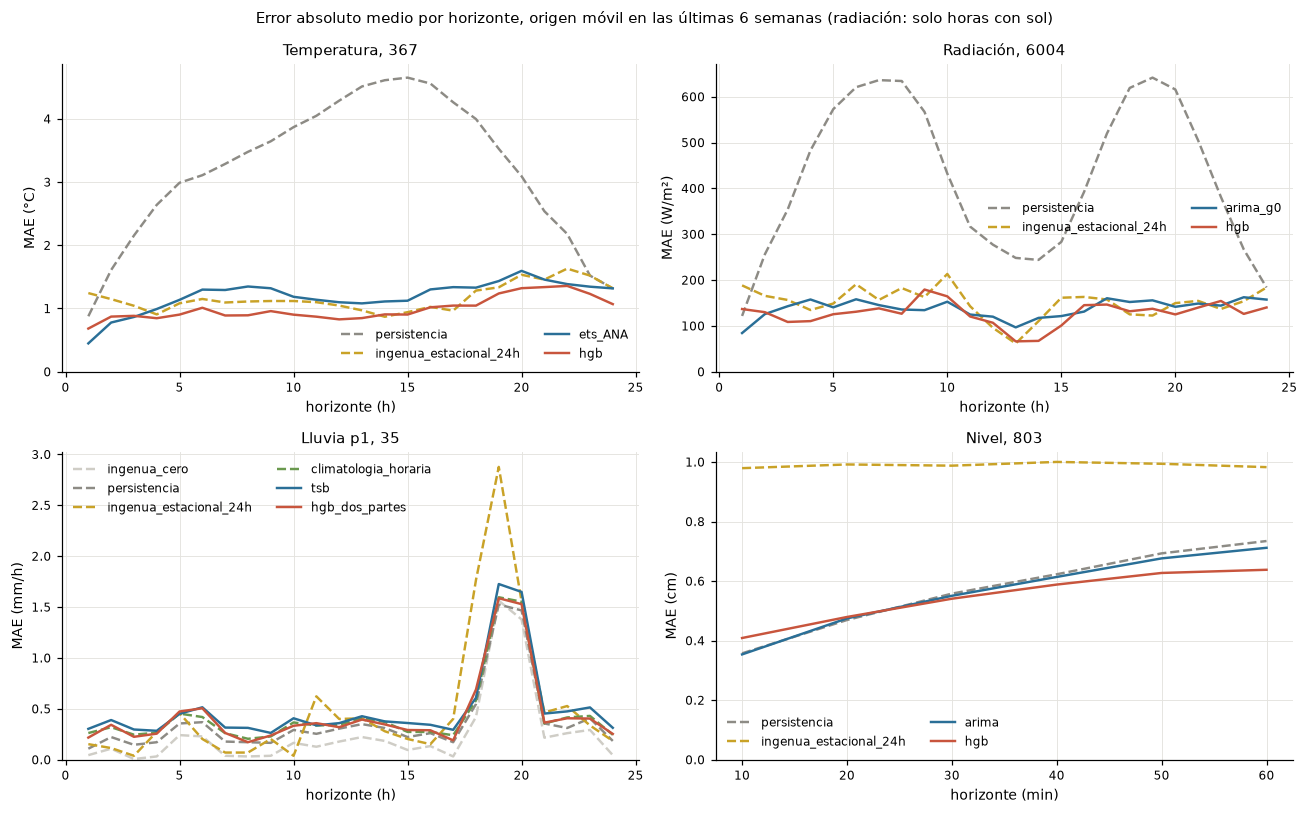

In [17]:
def por_h(v):
    d = pron[v]
    return S.por_horizonte(d[de_dia(d)] if v == "radiacion" else d)


horizonte = {v: por_h(v) for v in pron}
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
for a, v in zip(ax.flat, pron):
    for modelo, g in horizonte[v].groupby("modelo", sort=False):
        x = g["horizonte"] * (10 if v == "nivel" else 1)
        a.plot(x, g["MAE"], color=COLOR[modelo], label=modelo, ls="--" if modelo.startswith(("ingenua", "persist", "clima")) else "-")
    a.set(title=TITULO[v], xlabel="horizonte (min)" if v == "nivel" else "horizonte (h)", ylabel=f"MAE ({UNIDAD[v]})", ylim=(0, None))
    a.legend(ncols=2)
fig.suptitle("Error absoluto medio por horizonte, origen móvil en las últimas 6 semanas (radiación: solo horas con sol)", fontsize=10)
fig.tight_layout()
guardar(fig, "mae_horizonte")

## B5. Incertidumbre y calibración

Un intervalo del 80 % bien calibrado contiene el dato real en el 80 % de los casos. Más que eso es demasiado ancho (inútil para decidir); menos, demasiado optimista. Se reporta la cobertura empírica y el ancho medio, en total y por horizonte. Para el modelo de ML se compara el intervalo de cuantiles sin ajustar con el ajuste conformal (CQR): en cada origen el intervalo se ensancha (o encoge) con el cuantil de los errores de los orígenes anteriores cuyo dato real ya se conocía en ese momento.

In [18]:
pd.DataFrame(cqr)

,variable,modelo,intervalo,n,cobertura80,ancho80
0,t,hgb,cuantiles,910,0.760,3.041
1,t,hgb,CQR,910,0.843,3.463
2,radiacion,hgb,cuantiles,459,0.824,528.597
3,radiacion,hgb,CQR,459,0.821,529.588
4,p1,hgb_dos_partes,cuantiles,912,0.922,0.108
5,p1,hgb_dos_partes,CQR,912,0.922,0.108
6,nivel,hgb,cuantiles,7144,0.734,1.346
7,nivel,hgb,CQR,7144,0.777,1.493


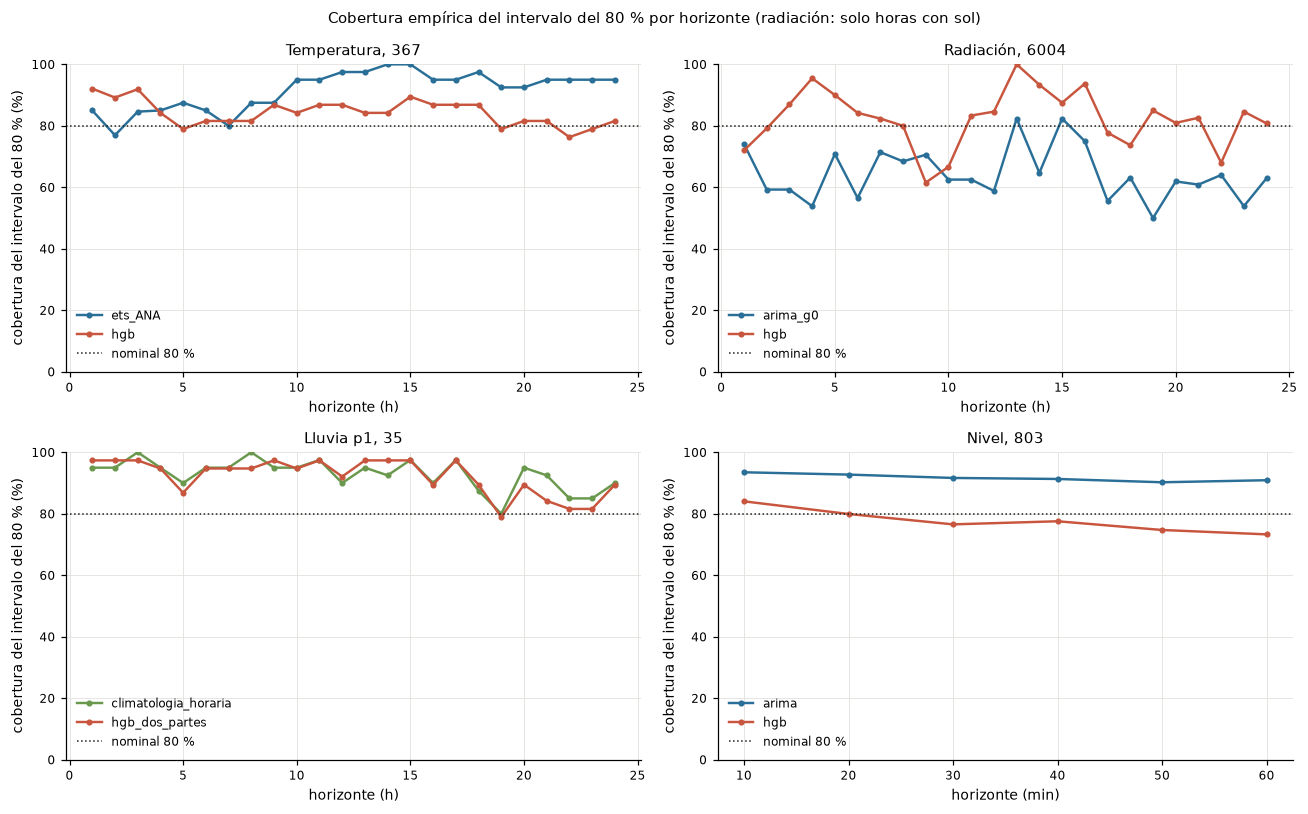

In [19]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
for a, v in zip(ax.flat, pron):
    for modelo, g in horizonte[v].dropna(subset=["cobertura80"]).groupby("modelo", sort=False):
        x = g["horizonte"] * (10 if v == "nivel" else 1)
        a.plot(x, 100 * g["cobertura80"], color=COLOR[modelo], label=modelo, marker="o", ms=3)
    a.axhline(80, color="#1f1e1c", lw=1, ls=":", label="nominal 80 %")
    a.set(title=TITULO[v], xlabel="horizonte (min)" if v == "nivel" else "horizonte (h)",
          ylabel="cobertura del intervalo del 80 % (%)", ylim=(0, 100))
    a.legend()
fig.suptitle("Cobertura empírica del intervalo del 80 % por horizonte (radiación: solo horas con sol)", fontsize=10)
fig.tight_layout()
guardar(fig, "cobertura_horizonte")

In [20]:
anchos = pd.concat([h.assign(variable=v) for v, h in horizonte.items()]).dropna(subset=["ancho80"])
anchos.pivot_table(index=["variable", "modelo"], columns="horizonte", values="ancho80").iloc[:, [0, 2, 5, 11, 23]].round(2)

horizonte                           1       3       6       12      24
variable  modelo                                                      
nivel     arima                   1.91    2.63    3.13     NaN     NaN
          hgb                     1.26    1.47    1.67     NaN     NaN
p1        climatologia_horaria    0.27    0.28    0.28    0.16    0.25
          hgb_dos_partes          0.29    0.15    0.16    0.05    0.16
radiacion arima_g0              205.44  286.69  315.76  292.78  309.54
          hgb                   544.22  491.38  496.69  460.48  542.01
t         ets_ANA                 1.89    3.27    4.63    6.55    9.26
          hgb                     3.34    3.39    3.22    3.00    3.96

### Lectura de B5

- Temperatura. El intervalo de ETS es demasiado ancho: el del 80 % cubre 91,5 % con 6,4 °C de ancho medio, y crece de 1,9 °C a 1 h a 9,3 °C a 24 h. ETS(A,N,A) trata el nivel como una caminata aleatoria cuya varianza se acumula con el horizonte, pero la temperatura vuelve a su ciclo cada día. El HGB con CQR cubre 84,3 % con 3,5 °C: cerca del nominal y con la mitad del ancho. El ajuste conformal corrigió la subcobertura de los cuantiles sin ajustar (de 76,0 % a 84,3 %).
- Radiación. El ARIMA sobre g0 se queda corto: 63,8 % en el intervalo del 80 % y 81,4 % en el del 95 %. Usa una sola varianza para día y noche, y el error de una hora con nubes es mucho mayor que ese promedio (heterocedasticidad). En el HGB los cuantiles sin ajustar cubren 82,4 % y el CQR 82,1 %, con casi el mismo ancho (529 W/m²): el ajuste conformal casi no movió el intervalo, que ya estaba cerca del nominal pero es ancho: sin información de nubes no hay cómo estrecharlo.
- Lluvia. Los intervalos del 80 % cubren entre 92 % y 93 %, pero miden de 0,11 a 0,23 mm: la mayoría de las veces son [0, 0], porque 91 % de las horas son secas. Dicen "no llueve" y fallan en los aguaceros; con lluvia intermitente la incertidumbre útil es la probabilidad (Brier).
- Nivel. ARIMA cubre 91,7 % con 2,6 cm (demasiado ancho en tiempo seco). El HGB con CQR cubre 77,7 % con 1,5 cm, cerca del nominal, pero la cobertura baja con el horizonte (84 % a 10 min, 73 % a 60 min), baja a 73 % en los orígenes con lluvia y a 6 % en las subidas con lluvia. Una salida es calibrar por régimen (por ejemplo, un CQR aparte para orígenes con lluvia) en vez de mezclar todos los errores.

### Ejemplos de pronóstico

Un origen por variable con su intervalo del 80 %: el último origen en temperatura y radiación, el origen cuyo horizonte tuvo más lluvia en la 35 y, en el nivel, el origen previo a la mayor subida con lluvia en las 2 h anteriores.

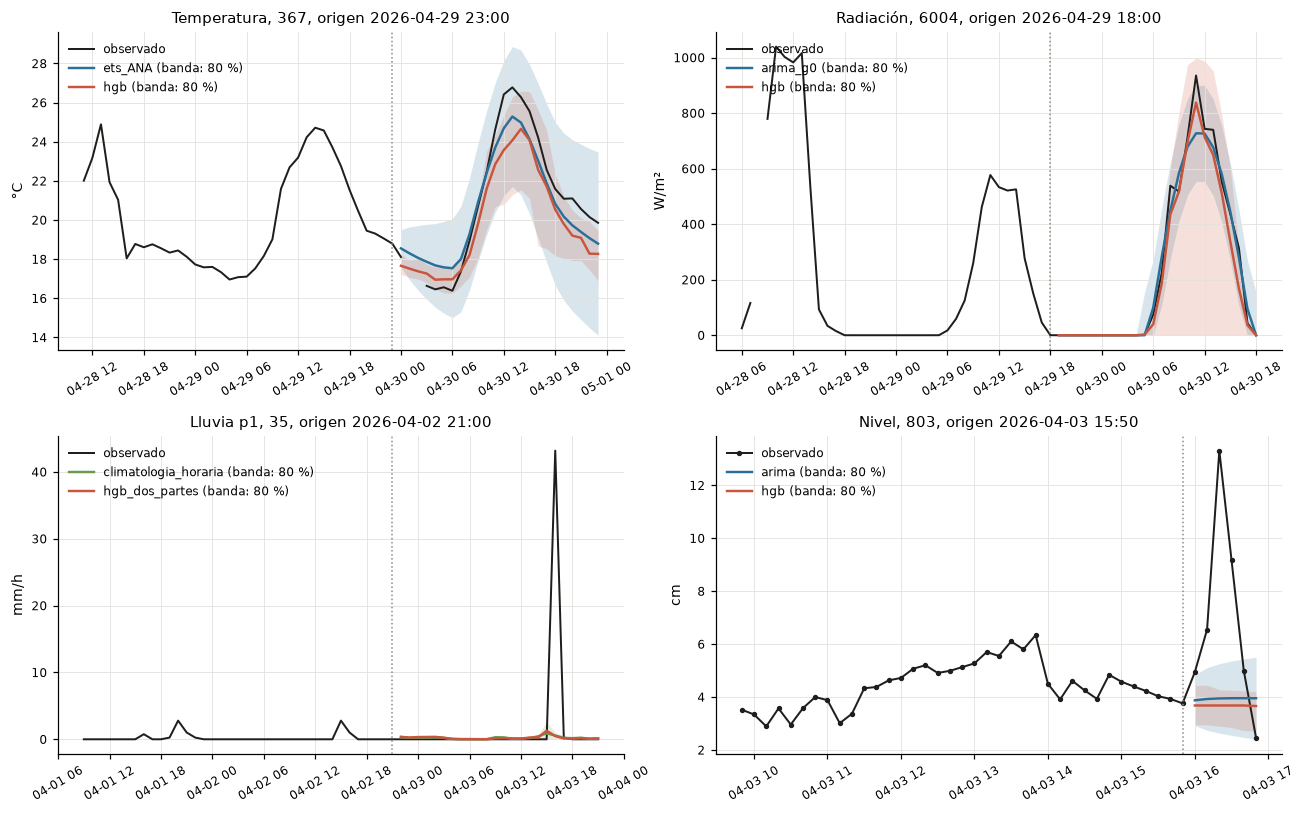

In [21]:
def origen_ejemplo(v):
    d = pron[v][pron[v]["modelo"] == "persistencia"]
    if v == "p1":
        return d.groupby("origen")["real"].sum().idxmax()
    if v == "nivel":  # la mayor subida con lluvia previa: la de mayor subida sin lluvia es un artefacto (ver arriba)
        s = subidas[subidas["con_lluvia"] & (subidas["modelo"] == "persistencia")]
        return s.loc[s["subida"].idxmax(), "origen"]
    return d["origen"].max()


PAR = {"t": ("ets_ANA", "hgb"), "radiacion": ("arima_g0", "hgb"), "p1": ("climatologia_horaria", "hgb_dos_partes"),
       "nivel": ("arima", "hgb")}
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
for a, v in zip(ax.flat, pron):
    o = origen_ejemplo(v)
    atras = pd.Timedelta("36h") if v != "nivel" else pd.Timedelta("6h")
    obs = objetivo[v].loc[o - atras:o + PERIODO[v] * objetivo[v].index.freq if v != "nivel" else o + 6 * objetivo[v].index.freq]
    a.plot(obs.index, obs, color="#1f1e1c", lw=1.3, marker="o" if v == "nivel" else None, ms=2.5, label="observado")
    for modelo in PAR[v]:
        g = pron[v][(pron[v]["modelo"] == modelo) & (pron[v]["origen"] == o)]
        a.fill_between(g["fecha_hora"], g["inf80"], g["sup80"], color=COLOR[modelo], alpha=0.18, lw=0)
        a.plot(g["fecha_hora"], g["pred"], color=COLOR[modelo], lw=1.6, label=f"{modelo} (banda: 80 %)")
    a.axvline(o, color="#8d8b85", ls=":", lw=1)
    a.set(title=f"{TITULO[v]}, origen {o:%Y-%m-%d %H:%M}", ylabel=UNIDAD[v])
    a.tick_params(axis="x", rotation=30)
    a.legend(loc="upper left")
fig.tight_layout()
guardar(fig, "ejemplos_pronostico")

## B6. Recomendación para operación

- Temperatura (367): HGB directo con intervalo CQR (MAE 0,99 °C, cobertura 84,3 %); para la próxima hora, ETS (0,45 °C). Falla si cambia el régimen que vio en cinco meses (otra temporada, un episodio más cálido: los árboles no extrapolan fuera del rango de entrenamiento), si un hueco largo deja sin rezagos el origen, o si el sensor deriva de a poco (el modelo aprende la deriva y no la avisa).
- Radiación (6004): HGB con g0 para el valor puntual; la regresión ARIMA sobre g0 si se prefiere algo más simple y con errores grandes algo menores. El intervalo del HGB con CQR cubre cerca del nominal (82 %), pero es ancho; el del ARIMA se queda corto (63,8 %). Falla si el reloj vuelve a cambiar: el archivo venía en UTC y g0 depende de la hora; un desfase de 5 h no rompe el modelo, lo deja pronosticando sol de noche, y sin un control de reloj nadie lo notaría. Sin información de nubes (satélite o radar) ningún modelo se aleja mucho de la ingenua estacional.
- Lluvia (35): no recomiendo pronosticar montos horarios con estos datos. La probabilidad de lluvia del clasificador es lo único que le gana a la climatología (BSS 0,27 a 1 h y 0,10 de 2 a 3 h), pero con solo 3 horas lluviosas en cada uno de esos bloques hay que validarla con más eventos antes de usarla en operación; mientras tanto, y para más de 3 h, la climatología horaria. Falla con el cambio de temporada (cinco meses, de diciembre a abril, no cubren el año) y con la lluvia convectiva que se forma en minutos; para eso hace falta el radar.
- Nivel (803): HGB con la lluvia de la 35 e intervalo CQR, entrenado desde el 3 de marzo. Es el mejor de los cuatro, pero la ganancia es pequeña (4 % en total, 8 % con lluvia) y no anticipa las subidas. Para alerta no lo usaría solo: va como complemento de umbrales de lluvia observada en la 35 y del pronóstico inmediato por radar. Falla si la 35 deja de transmitir (pierde su mejor variable), si la 803 vuelve a cambiar de instalación sin aviso como el 3 de marzo (otra línea base y otro ruido), y mientras el control de calidad deje pasar saltos sin lluvia como el del 30 de abril, que contaminan el entrenamiento y la evaluación. Antes de volver a entrenar propondría endurecer la regla de salto o la de pico sin lluvia del nivel, y recuperar las crecientes de antes del 3 de marzo corrigiendo su línea base para tener más eventos.

In [22]:
print(f"tiempo total del notebook: {(time.time() - INICIO) / 60:.1f} min")

tiempo total del notebook: 1.4 min
